# Lesson 5: Choose when to switch
## Hoof, Paper, Scissors

Run in Jupyter or Google Colab with Python 3. No packages or external input files are required. Shift+Enter runs a cell. Run the setup cell first. Predict each result before running code.

Exercise IDs match the worksheet and slides. Small recursive examples are for learning; use iteration for large inputs. Python stops recursion at about 1,000 nested calls by default, so recursive versions are for small inputs only.


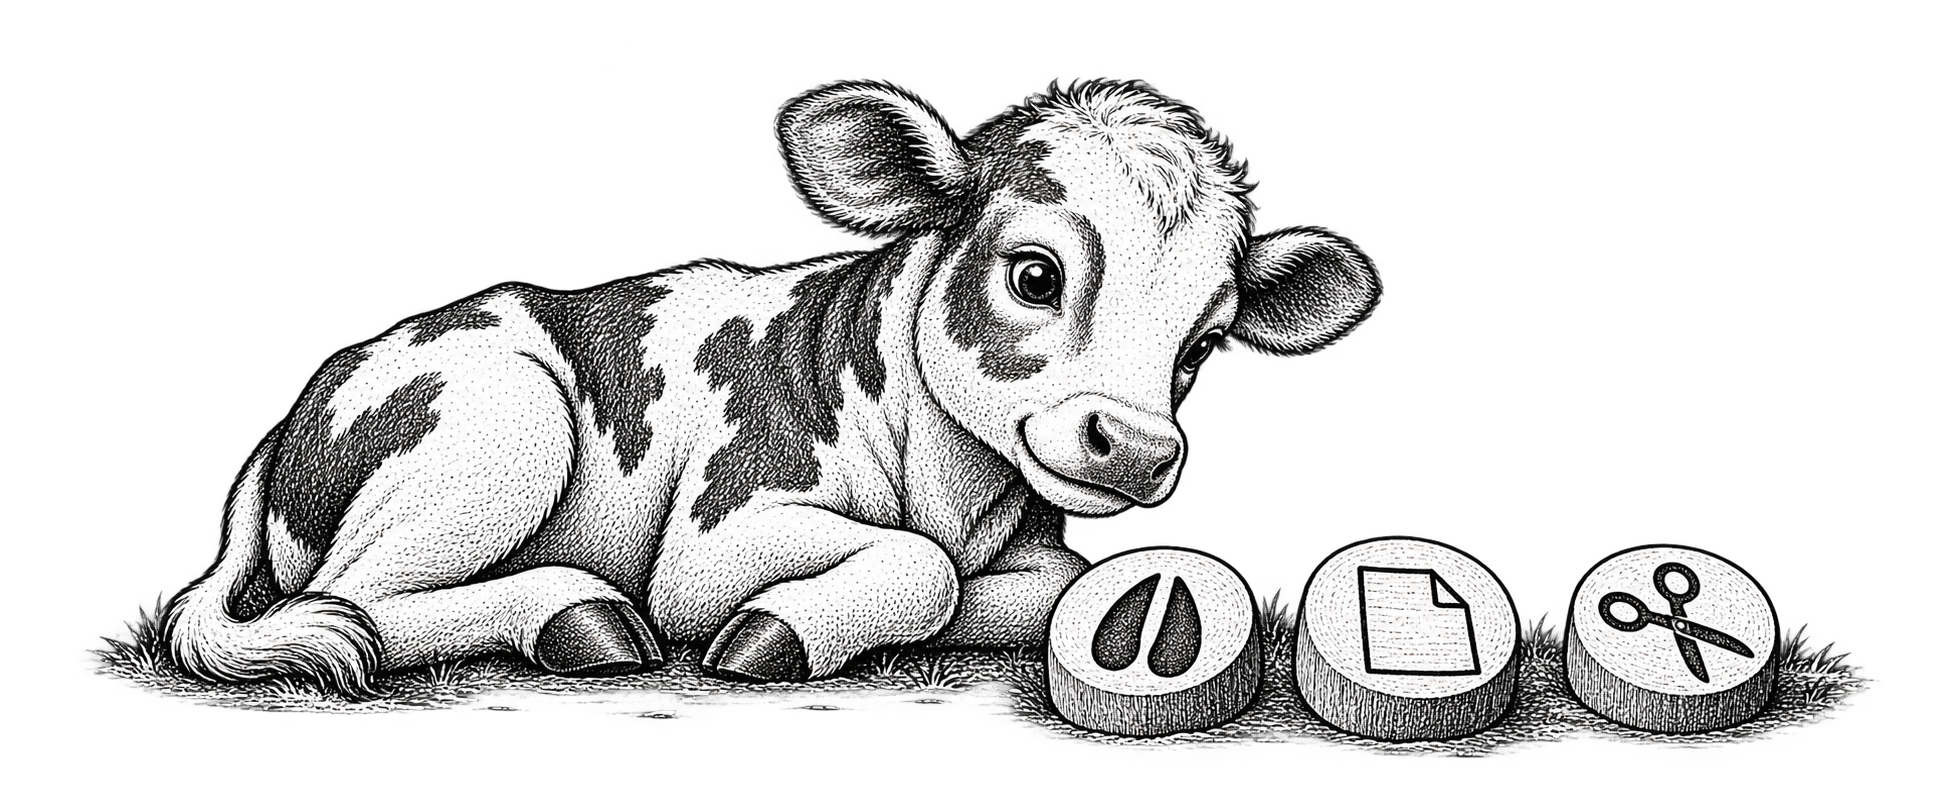

In [ ]:
from functools import lru_cache
BEATS = {'H': 'S', 'P': 'H', 'S': 'P'}
print('Ready. Run cells from top to bottom.')


## The route and the rules

### Our route
Count wins when one gesture is kept throughout. Then place one change by hand. To solve longer games, record the round, switches used and ending gesture. Compare keeping that gesture with changing it, and fill a fresh table for each round.

### Game rules
John's entire sequence is known in advance. Bessie chooses H (hoof), P (paper) or S (scissors) for each round. H beats S, S beats P, and P beats H. A win scores 1; a draw or loss scores 0. Maximise Bessie's total wins.

### Switch rules
The first gesture is free. A switch is a change of gesture between two consecutive rounds. The budget, called K in the judge's statement and budget in the code, allows at most that many changes, not exactly that many. For example, H, H, P uses one switch. Number rounds from 0, so round 2 is the third round.

### Names used in the questions
`used` is the number of switches already used (written `used` in the code too). `g` is the current gesture. A score cell stores the most wins among strategies with that exact used and g after the specified round. Two different strategies may contribute to the same cell; keep the better score.

### Reading the tables
The columns headed H, P and S identify Bessie's ending gesture, not John's move. Write a dash for a state that is impossible. A score of 0 instead means a legal strategy exists but has no wins. L5-06 connects the dash to the program's negative-infinity value.

## L5-01: Which gesture wins?

H means hoof, P paper and S scissors. H beats S, S beats P, and P beats H. A win scores 1; a draw or loss scores 0. John plays H, H, S, S, P. Fill Bessie's wins in each round when she keeps H throughout, then when she keeps P or S.

Round | 0 | 1 | 2 | 3 | 4
--- | --- | --- | --- | --- | ---
John | H | H | S | S | P
Keep H | ? | ? | ? | ? | ?
Keep P | ? | ? | ? | ? | ?
Keep S | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Keeping H wins twice, against the two S rounds. Keeping P wins twice, against the two H rounds. Keeping S wins once, against P. Draws and losses each contribute zero wins.

Write the direction of the winning relation explicitly. The letters H, P and S stand for hoof, paper and scissors. The goal is to maximise the number of wins, not to minimise losses or score draws.

John's entire sequence is known in advance. This is a planning problem, not a game against an opponent who reacts to our current choice. Bessie may select any first gesture for free. Only changing between rounds consumes a switch.

**Completed table:**

Round | 0 | 1 | 2 | 3 | 4
--- | --- | --- | --- | --- | ---
John | H | H | S | S | P
Keep H | 0 | 0 | 1 | 1 | 0
Keep P | 1 | 1 | 0 | 0 | 0
Keep S | 0 | 0 | 0 | 0 | 1

## L5-02: Zero switches is already a useful case

With no switches allowed, how would you solve the whole game? What answer do you get for H, H, S, S, P?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Count the wins for each fixed gesture and take the largest. The answer is 2. Choosing the first gesture is free, so all three fixed strategies are available.

This baseline gives a concrete interpretation for the switch budget. With budget zero, a legal strategy must keep one gesture throughout. The three possibilities are simple enough to enumerate.

If there are n rounds, there are still only three constant strategies, not 3 to the n. That exponential count describes arbitrary per-round choices before imposing the switch restriction. A good state-based solution must reduce to this zero-budget behaviour.

## L5-03: One well-placed switch

John plays H, H, S, S, P. Bessie may choose her first gesture freely and change it at most once between rounds. Find a strategy with four wins. Number rounds from 0 and identify the gap where she changes. Can one change produce five wins?

Round | 0 | 1 | 2 | 3 | 4
--- | --- | --- | --- | --- | ---
John | H | H | S | S | P
Bessie | ? | ? | ? | ? | ?
Wins | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Play P, P, H, H, H. Switch once before round 2 and win four rounds. Winning all five would require P, P, H, H, S, which changes twice. Thus 4 is optimal.

A strategy can be divided into runs of one gesture. One switch permits at most two runs. The given strategy wins the first two rounds with paper and the next two with hoof, then loses the last round.

To prove that five wins are impossible, identify the uniquely winning gesture for each of John's moves. The winning sequence has two boundaries where the gesture changes. Since only one is allowed, at least one round cannot be won. This is a small proof with a visible example before introducing a larger state table.

**Completed table:**

Round | 0 | 1 | 2 | 3 | 4
--- | --- | --- | --- | --- | ---
John | H | H | S | S | P
Bessie | P | P | H | H | H
Wins | 1 | 1 | 1 | 1 | 0

## L5-04: What must the state remember?

Two strategies have processed the same rounds and used one switch, but one ends with H and the other with P. Can their best win counts be merged into one number?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** No. Their current gestures differ, so the next gesture may require a switch in one history but not the other. Record the processed round, switches used and current gesture.

Position alone is insufficient, and even position plus switch usage is insufficient. The last gesture affects the cost of changing to the next one. Earlier details can be forgotten once these facts and the best score are known.

The iterative state will store the best wins after a certain number of rounds, using exactly used switches, and ending with gesture g. Here used is a resource count and g is a choice, not a score. The number stored in the cell is the win count. We will keep exact usage in the table and take a maximum over all permitted usages at the end.

## L5-05: Recursive choices with a budget

Write hps_cached(john, budget) using recursion. Its helper knows the next round, switches left and previous gesture. How do you handle the first round without charging a switch?

**Start with:**

```python
def hps_cached(john, budget):
    def best(i, left, previous):
        return None  # Your helper goes here.
    return best(0, budget, '')
```

**What each function returns:**
- `hps_cached(john, budget)`: the most rounds Bessie can win within the switch budget.
- `best(i, left, previous)`: the most further wins from round i, with left switches available and previous as the last gesture.

**Hints:**
- What does best return when no rounds remain?
- When does choosing a gesture cost a switch, and when is it free?
- Which choices are not allowed with the switches left?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Try each gesture. Charge one switch only if a previous gesture exists and the new one differs. Reject choices that exceed the remaining budget. Add this round's win to the best continuation.

The recursive function returns the most future wins from its state. It uses switches left, while the iterative table later uses switches already used. Make this change of viewpoint explicit. The first call uses an empty previous gesture to represent that no gesture has been chosen yet.

Without caching, arbitrary gesture choices create a large search tree. Caching merges calls with the same round, remaining budget and previous gesture. The local cache belongs to one fixed John sequence and budget. A recursive chain can still have one call per round, so use this as a small-instance explanation and move to iteration for large games.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def hps_cached(john, budget):
    @lru_cache(None)
    def best(i, left, previous):
        if i == len(john):
            return 0
        answer = 0
        for gesture in 'HPS':
            change = int(previous != '' and gesture != previous)
            if change <= left:
                win = int(BEATS[gesture] == john[i])
                answer = max(answer, win + best(i + 1, left - change, gesture))
        return answer
    return best(0, budget, '')


In [ ]:
print(hps_cached('HHSSP', 1))

## L5-06: Exactly used versus at most allowed

John plays H in round 0. Fill Bessie's scores for each ending gesture H, P and S with exactly zero switches used. Can exactly one switch have been used after just this round? Write a dash for impossible states and explain why a score of 0 would mean something different.

Switches used | End H | End P | End S
--- | --- | --- | ---
0 | ? | ? | ?
1 | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** For ending gestures H, P, S, the zero-switch scores are [0, 1, 0]. Exactly one switch is impossible after one round. Mark impossible states with negative infinity, not zero.

The table uses exact switch counts so a transition that changes gesture clearly moves from row used - 1 to row used. The original problem allows at most K switches, so the final answer considers every row from 0 through K.

A zero score means a real strategy with no wins. It must not also mean an impossible strategy. We use negative infinity for impossible states because taking a maximum will never prefer them over a real score. Adding a win to negative infinity still leaves it impossible. Initialising every row to zero would invent strategies that have already changed before a second round exists.

**Completed table:**

Switches used | End H | End P | End S
--- | --- | --- | ---
0 | 0 | 1 | 0
1 | impossible | impossible | impossible

## L5-07: Stay or switch before this round

After John plays H,H, scores for ending H,P,S are [0,2,0] with no switches and [1,1,1] with exactly one. John now plays S. For an ending H with exactly one switch, compare staying with H against changing from P or S. Then fill both new score rows.

After H,H,S | End H | End P | End S
--- | --- | --- | ---
0 switches | ? | ? | ?
1 switch | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Stay with H after one earlier switch: 1 + 1 = 2. Switch now from P: 2 + 1 = 3; from S: 0 + 1 = 1. Each candidate adds this round's win once. Keep 3. The complete rows are [1,2,0] for zero switches and [3,1,2] for exactly one.

To compute a cell for current gesture g and exactly used switches, compare two kinds of predecessor. Staying reads the previous table at the same used and g. Switching reads row used - 1 at another gesture. Then add one if g beats the current opponent.

The win depends only on the gesture for this round and John's move. It must be added to the chosen predecessor score once, not once for each candidate. For the three-round prefix H,H,S, the complete zero-switch row becomes [1,2,0], and the one-switch row becomes [3,1,2].

**Completed table:**

After H,H,S | End H | End P | End S
--- | --- | --- | ---
0 switches | 1 | 2 | 0
1 switch | 3 | 1 | 2

## L5-08: Trace all five rounds

Trace John's rounds H,H,S,S,P. In each table column, 0 or 1 is the exact number of switches used; H, P or S is Bessie's ending gesture. Fill every row from the row immediately above it. A dash means impossible. Which final entry gives the best score with at most one switch?

John prefix | 0: H | 0: P | 0: S | 1: H | 1: P | 1: S
--- | --- | --- | --- | --- | --- | ---
H | 0 | 1 | 0 | - | - | -
HH | ? | ? | ? | ? | ? | ?
HHS | ? | ? | ? | ? | ? | ?
HHSS | ? | ? | ? | ? | ? | ?
HHSSP | ? | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** After all five rounds, zero-switch scores are [2,2,1] and one-switch scores are [4,2,3]. The largest score across both rows is 4, ending with H after one switch.

Use a separate pair of rows for each time step during the hand trace. This prevents the time dimension from disappearing before students understand it. The first round is initialised directly. Each later round reads only the immediately previous table.

After H,H the zero-switch row is [0,2,0] and the one-switch row is [1,1,1]. After H,H,S the rows are [1,2,0] and [3,1,2]. After H,H,S,S they are [2,2,0] and [4,1,2]. After the final P, S gains a win and the best H strategy remains at four. Ask students to explain one cell rather than only copying all numbers.

**Completed table:**

John prefix | 0: H | 0: P | 0: S | 1: H | 1: P | 1: S
--- | --- | --- | --- | --- | --- | ---
H | 0 | 1 | 0 | - | - | -
HH | 0 | 2 | 0 | 1 | 1 | 1
HHS | 1 | 2 | 0 | 3 | 1 | 2
HHSS | 2 | 2 | 0 | 4 | 1 | 2
HHSSP | 2 | 2 | 1 | 4 | 2 | 3

## L5-09: Keep just the previous round

Write hps_table(john, budget) using a loop over rounds. Here used counts switches already used and g is the ending gesture. before[used][g] stores the best score after the previous round; now[used][g] includes the current round. Compare staying and switching. Why must now be fresh? Return the best score using at most budget switches (K in the original statement).

**Start with:**

```python
def hps_table(john, budget):
    return None  # Replace with your answer.
```

**What each function returns:**
- `hps_table(john, budget)`: the most rounds Bessie can win within the switch budget.

**Hints:**
- What are the scores after round 0, and which states are impossible then?
- For a new cell, which cells of before lead to it by staying, and which by switching?
- What should an impossible state hold so that max ignores it?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** before holds completed scores for the previous round; now holds scores for the current round. Keep the old table unchanged while all new cells are calculated, so a round cannot be counted twice. For at most K switches, return the maximum over every ending gesture and every usage row from 0 to K.

The gesture string HPS maps indices 0, 1 and 2 to the actual gesture letters. The BEATS dictionary maps a gesture to the opponent it defeats. enumerate gives both an index and its corresponding gesture. The program tests old != g when spending a switch.

For each round, there are K + 1 usage rows and three gesture columns. Each cell examines at most two alternate gestures, giving O(N times (K + 1)) work and O(K + 1) memory. The full time table would use O(N times (K + 1)) memory, but only adjacent rounds are needed. The code returns the maximum over all usage rows, respecting the at-most budget.

In [ ]:
def hps_table(john, budget):
    if not john:
        return 0
    gestures = 'HPS'
    impossible = -float('inf')
    before = [[impossible] * 3 for _ in range(budget + 1)]
    for g, gesture in enumerate(gestures):
        before[0][g] = int(BEATS[gesture] == john[0])
    for opponent in john[1:]:
        now = [[impossible] * 3 for _ in range(budget + 1)]
        for used in range(budget + 1):
            for g, gesture in enumerate(gestures):
                best_before = before[used][g]
                if used > 0:
                    for old in range(3):
                        if old != g:
                            best_before = max(best_before, before[used - 1][old])
                now[used][g] = best_before + int(BEATS[gesture] == opponent)
        before = now
    return int(max(max(row) for row in before))


In [ ]:
print(hps_table('HHSSP', 1))

## L5-10: Your turn: three different budgets

Test your hps_table(john, budget) from L5-09. For John = H,P,S, predict the best win count with budgets 0, 1 and 2. Give one strategy for each budget, then run your function.

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Budget 0: 1 win, for example P,P,P. Budget 1: 2 wins, for example P,S,S. Budget 2: 3 wins with P,S,H. The first gesture is free in every case.

Every round has a different uniquely winning gesture. With no switches we can win only one. With one switch we can choose two runs and win two rounds. With two switches we can match all three winning gestures.

These tests target budget handling directly. Students should predict all three outputs before using the program. Increasing the allowed budget cannot make the optimal answer smaller, because every strategy allowed before remains available. That monotonicity is a useful additional debugging check, not a replacement for exact expected answers.

In [ ]:
def hps_table(john, budget):
    if not john:
        return 0
    gestures = 'HPS'
    impossible = -float('inf')
    before = [[impossible] * 3 for _ in range(budget + 1)]
    for g, gesture in enumerate(gestures):
        before[0][g] = int(BEATS[gesture] == john[0])
    for opponent in john[1:]:
        now = [[impossible] * 3 for _ in range(budget + 1)]
        for used in range(budget + 1):
            for g, gesture in enumerate(gestures):
                best_before = before[used][g]
                if used > 0:
                    for old in range(3):
                        if old != g:
                            best_before = max(best_before, before[used - 1][old])
                now[used][g] = best_before + int(BEATS[gesture] == opponent)
        before = now
    return int(max(max(row) for row in before))


In [ ]:
checks = [
    (hps_table('HPS', 0), 1),
    (hps_table('HPS', 1), 2),
    (hps_table('HPS', 2), 3),
    (hps_table('HHSSP', 1), 4),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L5-11: More switches need not help

Test your hps_table(john, budget) from L5-09 on John = H,H,H with budgets 0 and 2, and on one round against S with budget 0. Predict each answer before running it. What should happen when the budget exceeds the useful number of changes?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** For H,H,H, both budgets give 3 wins by keeping P. For one S round the answer is 1 by choosing H, with no switch needed. Extra budget never forces extra changes.

The exact-use rows with excessive usage remain impossible, but the final maximum also considers the reachable smaller usages. This is why returning only row K would be wrong with the chosen state definition.

If K is larger than the number of gaps between rounds, those higher exact-use rows remain impossible throughout. The classroom solver handles this naturally. For efficiency a production implementation could cap the budget at N - 1, but this is optional and should not obscure the state meaning.

In [ ]:
def hps_table(john, budget):
    if not john:
        return 0
    gestures = 'HPS'
    impossible = -float('inf')
    before = [[impossible] * 3 for _ in range(budget + 1)]
    for g, gesture in enumerate(gestures):
        before[0][g] = int(BEATS[gesture] == john[0])
    for opponent in john[1:]:
        now = [[impossible] * 3 for _ in range(budget + 1)]
        for used in range(budget + 1):
            for g, gesture in enumerate(gestures):
                best_before = before[used][g]
                if used > 0:
                    for old in range(3):
                        if old != g:
                            best_before = max(best_before, before[used - 1][old])
                now[used][g] = best_before + int(BEATS[gesture] == opponent)
        before = now
    return int(max(max(row) for row in before))


In [ ]:
checks = [
    (hps_table('HHH', 0), 3),
    (hps_table('HHH', 2), 3),
    (hps_table('S', 0), 1),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L5-12: The state is the explanation

Choose a cell from the five-round score table and explain its round, exact switch count, ending gesture and stored score. Why can we forget the earlier gesture sequence once these facts and its best score are known? Compare this with Tower or Array Description.

John prefix | Switches used | Ending gesture | Stored score
--- | --- | --- | ---
&nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** After H,H,S, the cell for exactly one switch and ending H stores 3: P,P,H wins every round. A worse strategy at that same round, usage and gesture cannot improve future choices: it has the same remaining moves but fewer wins. Tower similarly keeps position and next player; Array Description keeps position and previous value.

Finish the course by comparing all four kinds of stored answers: counts, minimum costs, reachability flags and maximum scores. Their operations differ because their questions differ. Addition, min, logical marking and max are consequences of those meanings.

A good final explanation identifies the state, the legal transitions, the stopping or starting cases, the computation order and the returned answer. If students can explain these in their own words, they have more than a memorised template. Keep optional memory optimisations separate from this core understanding.

**Completed table:**

John prefix | Switches used | Ending gesture | Stored score
--- | --- | --- | ---
HHS | 1 | H | 3

## Original problem sources
- [Hoof, Paper, Scissors - USACO January 2017 Gold, problem 2](https://www.usaco.org/index.php?page=viewproblem2&cpid=694)